# 05 - Random Forest
Capped RUL target, official evaluation. `min_samples_leaf` and `max_features` regularise the trees.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

# Find the project root (the folder containing utils.py) no matter where the kernel was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "utils.py").exists())
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
import utils as U

In [2]:
ds = U.load_dataset()               # features, capped targets, engine-wise train/val split, official test targets
tr = ~ds.is_val
print("train rows:", tr.sum(), "| val rows:", ds.is_val.sum(), "| test engines:", len(ds.y_test))

train rows: 16138 | val rows: 4493 | test engines: 100


In [3]:
def report(name, val_pred, test_pred):
    """Validation = all rows of the 20 held-out training engines (capped RUL).
    Test = official protocol: ONE prediction per test engine (last observed cycle) vs RUL_FD001."""
    v = U.score_predictions(ds.y_train[ds.is_val], val_pred)
    t = U.score_predictions(ds.y_test, test_pred)
    print(f"{name}\n  validation  RMSE {v['RMSE']:.2f}  MAE {v['MAE']:.2f}  R2 {v['R2']:.3f}")
    print(f"  test (official)  RMSE {t['RMSE']:.2f}  MAE {t['MAE']:.2f}  R2 {t['R2']:.3f}  NASA score {t['NASA']:.0f}")
    return t

def scatter(test_pred, title):
    plt.figure(figsize=(5, 5))
    plt.scatter(ds.y_test, test_pred, alpha=0.7)
    lim = max(ds.y_test.max(), test_pred.max()) + 5
    plt.plot([0, lim], [0, lim], "r--"); plt.xlabel("True RUL"); plt.ylabel("Predicted RUL")
    plt.title(title); plt.grid(alpha=0.3); plt.show()

base = U.score_predictions(ds.y_test, np.full(len(ds.y_test), ds.train_mean_rul))
print(f"Reference - always predicting the mean training RUL: test RMSE {base['RMSE']:.2f}")

Reference - always predicting the mean training RUL: test RMSE 52.62


Random Forest (train on 80 engines)
  validation  RMSE 18.96  MAE 14.20  R2 0.789
  test (official)  RMSE 17.80  MAE 13.13  R2 0.816  NASA score 768


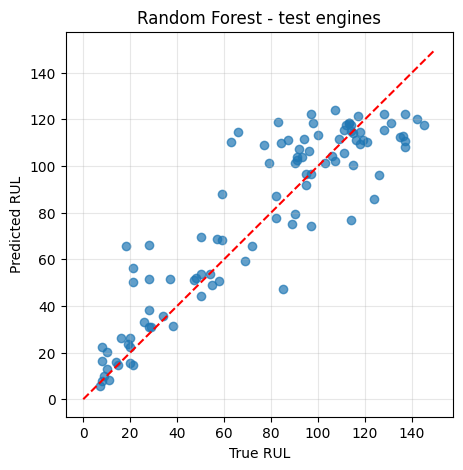

In [4]:
from sklearn.ensemble import RandomForestRegressor

params = dict(n_estimators=200, min_samples_leaf=5, max_features=0.5, n_jobs=-1, random_state=42)
model = RandomForestRegressor(**params).fit(ds.X_train.tab[tr], ds.y_train[tr])
val_pred  = model.predict(ds.X_train.tab[ds.is_val])
test_pred = model.predict(ds.X_test.tab.iloc[ds.last_idx])
report("Random Forest (train on 80 engines)", val_pred, test_pred)
scatter(test_pred, "Random Forest - test engines")

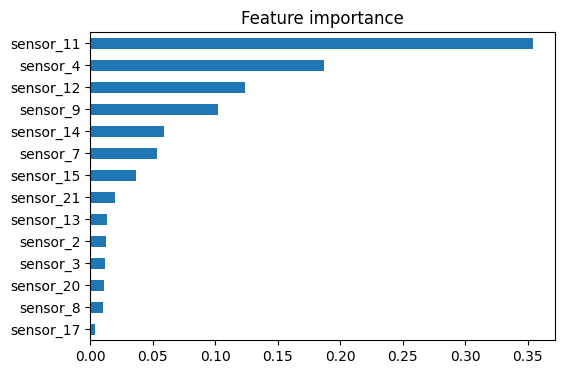

In [5]:
imp = pd.Series(model.feature_importances_, index=U.FEATURES).sort_values()
imp.plot.barh(figsize=(6, 4), title="Feature importance"); plt.show()

In [6]:
# Final model on all 100 training engines
final = RandomForestRegressor(**params).fit(ds.X_train.tab, ds.y_train)
test_pred = final.predict(ds.X_test.tab.iloc[ds.last_idx])
t = U.score_predictions(ds.y_test, test_pred)
print("final test RMSE", round(t["RMSE"], 2), "| NASA score", round(t["NASA"]))
joblib.dump(final, U.MODEL_DIR / "random_forest_model.pkl", compress=3)

final test RMSE 18.03 | NASA score 842


['/home/aryan/tt/NASA-C-MAPSS/claud/models/random_forest_model.pkl']